In [38]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import cv2 as cv

In [39]:
def image_points_to_world_at_z(M, points_2d, z):
    n = len(points_2d)
    A = np.linalg.inv(M[:, [0, 1, 3]])
    b = M[:, 2:3]
    points_h = np.concatenate((points_2d.T, [[1] * n]), 0)
    out = A @ (points_h - z * b)
    return (out[:-1] / out[-1]).T

def project_point(M, points, z):
    return image_points_to_world_at_z(M, points, z)

def calibrate_from_points(points2d, points3d):

    A = np.zeros((points2d.shape[0] * 2, 12))

    for i in range(points2d.shape[0]):
        x, y = points2d[i]
        X, Y, Z = points3d[i]

        # Composing matrix A
        A[2*i] = [X, Y, Z, 1, 0, 0, 0, 0, -x*X, -x*Y, -x*Z, -x]
        A[2*i + 1] = [0, 0, 0, 0, X, Y, Z, 1, -y*X, -y*Y, -y*Z, -y]

    # Solve m with SVD
    _, _, Vt = np.linalg.svd(A)
    m = Vt[-1]

    return m.reshape(3, 4)

def calibrate_norm(points2d, points3d):

    x_avg = np.mean(points2d[:, 0])
    y_avg = np.mean(points2d[:, 1])
    d_avg = np.mean(np.sqrt((points2d[:, 0] - x_avg)**2 + (points2d[:, 1] - y_avg)**2))

    T = np.array([[np.sqrt(2)/d_avg, 0, -np.sqrt(2)*x_avg/d_avg],
                  [0, np.sqrt(2)/d_avg, -np.sqrt(2)*y_avg/d_avg],
                  [0, 0, 1]])
    
    X_avg = np.mean(points3d[:, 0])
    Y_avg = np.mean(points3d[:, 1])
    Z_avg = np.mean(points3d[:, 2])
    D_avg = np.mean(np.sqrt((points3d[:, 0] - X_avg)**2 + (points3d[:, 1] - Y_avg)**2 + (points3d[:, 2] - Z_avg)**2))

    U = np.array([[np.sqrt(3)/D_avg, 0, 0, -np.sqrt(3)*X_avg/D_avg],
                  [0, np.sqrt(3)/D_avg, 0, -np.sqrt(3)*Y_avg/D_avg],
                  [0, 0, np.sqrt(3)/D_avg, -np.sqrt(3)*Z_avg/D_avg],
                  [0, 0, 0, 1]])

    normalized_2d_pts = (T @ np.hstack((points2d, np.ones((points2d.shape[0], 1)))).T).T[:, :2]
    normalized_3d_pts = (U @ np.hstack((points3d, np.ones((points3d.shape[0], 1)))).T).T[:, :3]

    M = calibrate_from_points(normalized_2d_pts, normalized_3d_pts)

    denormalized_M = np.linalg.inv(T) @ M @ U

    return denormalized_M

def calibrate_planar_from_points(points2d, points3d_xy):
    # Homography DLT (2D-2D): all world points share Z=0, so only 8 DOF are
    # observable. Solving this directly avoids the singular 3x4 matrix you get
    # from feeding coplanar points into the general 3D DLT.
    n = points2d.shape[0]
    A = np.zeros((n * 2, 9))

    for i in range(n):
        x, y = points2d[i]
        X, Y = points3d_xy[i]

        A[2*i] = [X, Y, 1, 0, 0, 0, -x*X, -x*Y, -x]
        A[2*i + 1] = [0, 0, 0, X, Y, 1, -y*X, -y*Y, -y]

    _, _, Vt = np.linalg.svd(A)
    h = Vt[-1]

    return h.reshape(3, 3)

def calibrate_planar_norm(points2d, points3d_xy):
    x_avg = np.mean(points2d[:, 0])
    y_avg = np.mean(points2d[:, 1])
    d_avg = np.mean(np.sqrt((points2d[:, 0] - x_avg)**2 + (points2d[:, 1] - y_avg)**2))

    T = np.array([[np.sqrt(2)/d_avg, 0, -np.sqrt(2)*x_avg/d_avg],
                  [0, np.sqrt(2)/d_avg, -np.sqrt(2)*y_avg/d_avg],
                  [0, 0, 1]])

    X_avg = np.mean(points3d_xy[:, 0])
    Y_avg = np.mean(points3d_xy[:, 1])
    D_avg = np.mean(np.sqrt((points3d_xy[:, 0] - X_avg)**2 + (points3d_xy[:, 1] - Y_avg)**2))

    U = np.array([[np.sqrt(2)/D_avg, 0, -np.sqrt(2)*X_avg/D_avg],
                  [0, np.sqrt(2)/D_avg, -np.sqrt(2)*Y_avg/D_avg],
                  [0, 0, 1]])

    normalized_2d_pts = (T @ np.hstack((points2d, np.ones((points2d.shape[0], 1)))).T).T[:, :2]
    normalized_3d_pts = (U @ np.hstack((points3d_xy, np.ones((points3d_xy.shape[0], 1)))).T).T[:, :2]

    H = calibrate_planar_from_points(normalized_2d_pts, normalized_3d_pts)

    denormalized_H = np.linalg.inv(T) @ H @ U

    return denormalized_H

def homography_to_projection_matrix(H):
    # Pads a world(X,Y)->image homography into the 3x4 shape that
    # image_points_to_world_at_z expects, with a zero Z column. Only valid at
    # z=0 (the plane the calibration points were measured on) -- exists so the
    # rest of the notebook can keep calling
    # image_points_to_world_at_z(M, points, z=0) unchanged.
    M = np.zeros((3, 4))
    M[:, [0, 1, 3]] = H
    return M

def img_to_world(points, calib, z):
    n = len(points)
    points = np.concatenate((points.T, [[1] * n]), 0)
    # Backward-compatible alias. Prefer image_points_to_world_at_z.
    return image_points_to_world_at_z(calib, points, z)

def select_points(img, scale_factor=.3):
    points = []

    def click_event(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN:
            original_x = int(x / scale_factor)
            original_y = int(y / scale_factor)
            points.append((original_x, original_y))

            cv.circle(param, (x, y), 3, (0, 255, 0), -1)
            cv.imshow("Image", param)

    # Resize image for display
    height, width = img.shape
    new_height, new_width = int(height * scale_factor), int(width * scale_factor)
    resized_img = cv.cvtColor(cv.resize(img, (new_width, new_height), interpolation=cv.INTER_LINEAR), cv.COLOR_GRAY2BGR)

    cv.imshow("Image", resized_img)
    cv.setMouseCallback("Image", click_event, resized_img)

    # Stop when esc pressed
    while True:
        key = cv.waitKey(20) & 0xFF
        if key == 27:  # ESC key to break
            break
        if cv.getWindowProperty("Image", cv.WND_PROP_VISIBLE) < 1:  # Check if window is closed
            break
    cv.destroyAllWindows()

    plt.figure(figsize=(18, 9))
    plt.imshow(cv.cvtColor(resized_img, cv.COLOR_BGR2RGB))
    plt.tight_layout()
    plt.axis("off")
    plt.show()
    return points

def refine_points(img, points, crop_size=100, zoom_factor=8):
    """
    Refine roughly-picked points by re-clicking on a zoomed crop around each one.

    For every point, shows a `crop_size` x `crop_size` area of the original
    (full-resolution) image around it, scaled up by `zoom_factor`, with the
    original selection drawn as a semi-transparent red dot.

    Controls: click = set the refined point and automatically advance to the
    next point, r = reset the marker to the original point (before clicking),
    Esc = keep the original point for this and all remaining points and stop
    refining.
    """
    half = crop_size // 2
    height, width = img.shape[:2]
    is_color = img.ndim == 3
    refined = list(points)

    for i, (x, y) in enumerate(points):
        x0, y0 = max(0, x - half), max(0, y - half)
        x1, y1 = min(width, x + half), min(height, y + half)
        crop = img[y0:y1, x0:x1]
        crop = crop.copy() if is_color else cv.cvtColor(crop, cv.COLOR_GRAY2BGR)

        zoomed_w, zoomed_h = crop.shape[1] * zoom_factor, crop.shape[0] * zoom_factor
        orig_zoomed = ((x - x0) * zoom_factor, (y - y0) * zoom_factor)
        selected = [x, y]  # refined point, in original image coordinates
        confirmed = [False]

        window_name = f"Refine point {i + 1}/{len(points)}  (click=select & continue, r=reset, esc=stop)"

        def render():
            zoomed = cv.resize(crop, (zoomed_w, zoomed_h), interpolation=cv.INTER_NEAREST)
            # original selection: semi-transparent dot
            overlay = zoomed.copy()
            cv.circle(overlay, orig_zoomed, max(3, zoom_factor // 2), (0, 0, 255), -1)
            zoomed = cv.addWeighted(overlay, 0.4, zoomed, 0.6, 0)
            # current refined selection: solid dot
            sel_zoomed = (int((selected[0] - x0) * zoom_factor), int((selected[1] - y0) * zoom_factor))
            cv.circle(zoomed, sel_zoomed, max(2, zoom_factor // 3), (0, 255, 0), -1)
            return zoomed

        def click_event(event, ex, ey, flags, param):
            if event == cv.EVENT_LBUTTONDOWN:
                selected[0] = x0 + int(round(ex / zoom_factor))
                selected[1] = y0 + int(round(ey / zoom_factor))
                cv.imshow(window_name, render())
                confirmed[0] = True

        cv.imshow(window_name, render())
        cv.setMouseCallback(window_name, click_event)

        stop = False
        while True:
            key = cv.waitKey(20) & 0xFF
            if confirmed[0]:
                cv.waitKey(150)  # brief pause so the confirmed point is visible before advancing
                break
            elif key in (ord('r'), ord('R')):  # reset marker to the original point
                selected[0], selected[1] = x, y
                cv.imshow(window_name, render())
            elif key == 27:  # Esc: stop refining
                stop = True
                break
            if cv.getWindowProperty(window_name, cv.WND_PROP_VISIBLE) < 1:
                stop = True
                break

        cv.destroyWindow(window_name)
        if stop:
            break
        refined[i] = (selected[0], selected[1])

    # Preview all refined points over the full image
    preview = img.copy() if is_color else cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    for px, py in refined:
        cv.circle(preview, (int(px), int(py)), 5, (0, 255, 0), -1)

    plt.figure(figsize=(18, 9))
    plt.imshow(cv.cvtColor(preview, cv.COLOR_BGR2RGB))
    plt.tight_layout()
    plt.axis("off")
    plt.show()

    return refined

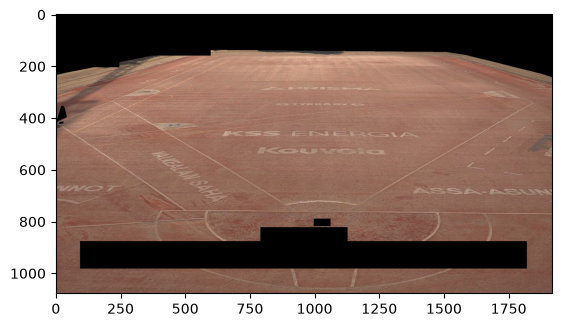

In [40]:
# Base image used for camera calibration
img = cv.imread('img/kopla.png')
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.show()

points_3d = pd.read_csv('calibration_points.csv', header=0)
points_x = points_3d['x'].values
points_y = points_3d['y'].values
points_z = points_3d['z'].values

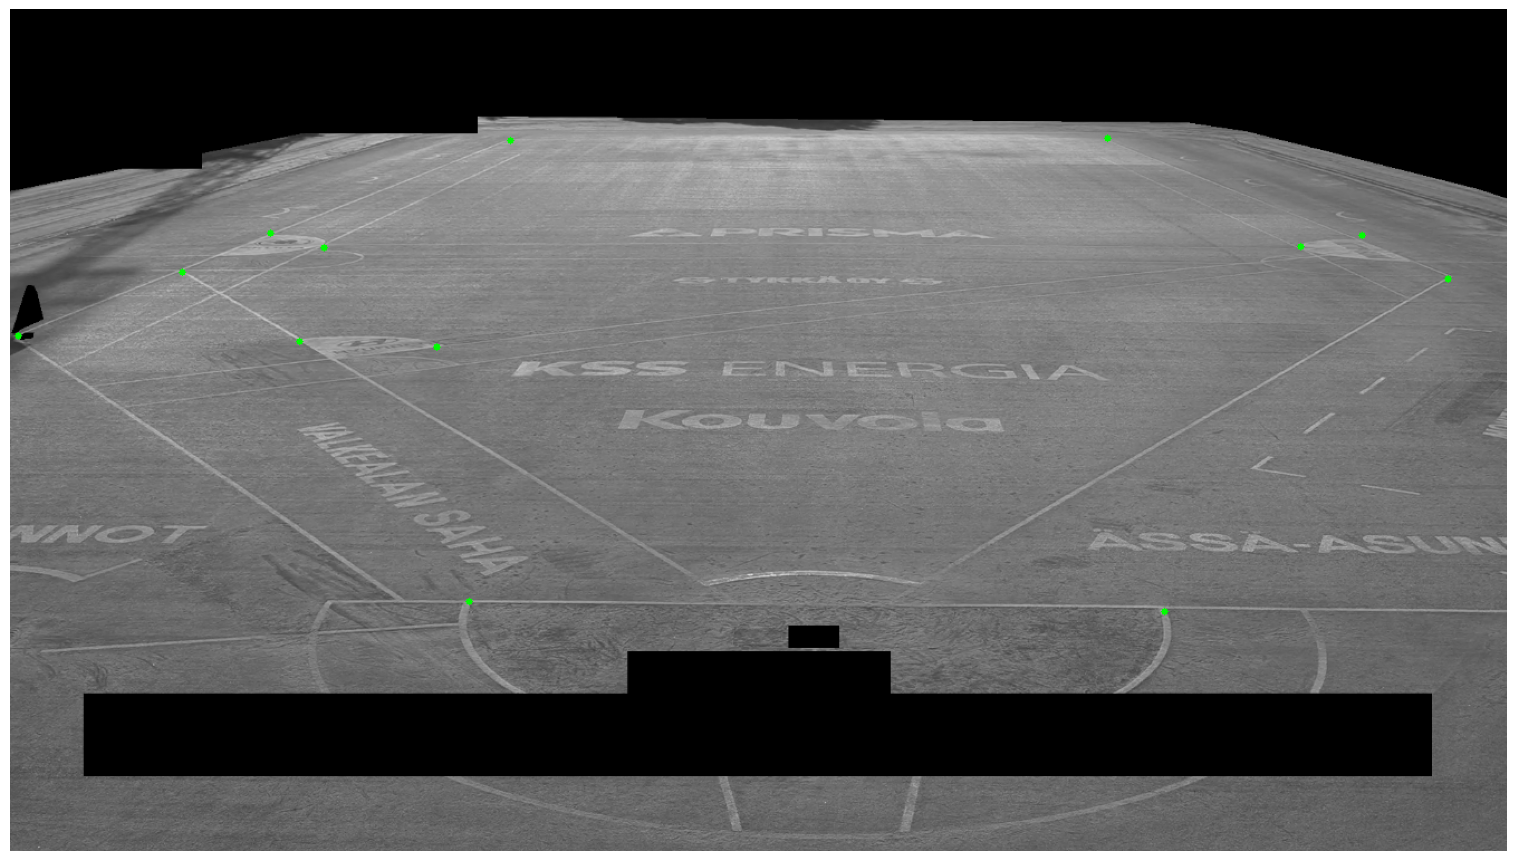

In [41]:
# Select 2d points from the image, pick by hand, and save them to a csv file
points_2d = select_points(cv.cvtColor(img, cv.COLOR_BGR2GRAY), scale_factor=0.7)

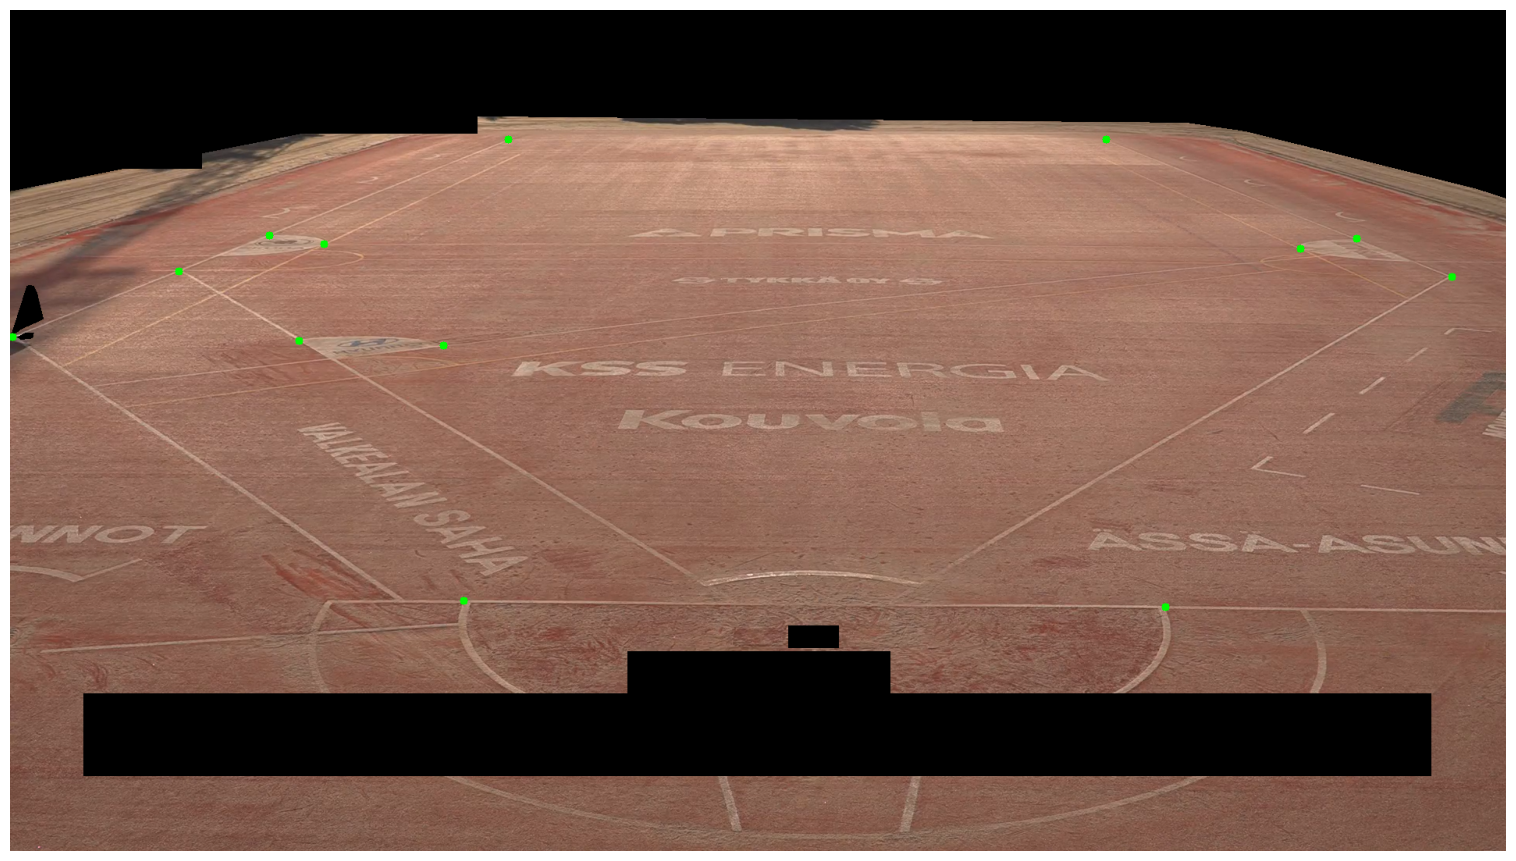

In [42]:
# Refine the roughly-selected points: zoom into a 100x100 area around each
# one and re-click for better accuracy. The original click is shown as a
# semi-transparent red dot; click to place the refined point, which
# automatically advances to the next one (r = reset, esc = stop early).
points_2d = refine_points(img, points_2d, crop_size=100, zoom_factor=8)

In [43]:
points_2d_df = pd.DataFrame(points_2d, columns=['x', 'y'])
points_2d_df.to_csv('calibration_points_2d.csv', index=False)

In [44]:
# Calibrate the camera using the 2D image points and 3D (well, planar: Z is
# always 0) world points. All calibration points lie on the same plane, so a
# full 3x4 DLT is under-constrained (it produced a singular matrix); use a
# planar homography instead.
H = calibrate_planar_norm(np.array(points_2d), points_3d[['x', 'y']].values)
calibration_matrix = homography_to_projection_matrix(H)

In [45]:
# Build a bird's-eye (top-down) view by inverse-warping the photo directly
# into a canvas defined in world (field) coordinates, instead of mapping every
# source pixel to world space one at a time. That per-pixel approach is what
# produced the runaway values above: pixels near/above the horizon map to
# world coordinates near/behind infinity through a ground-plane homography.
# Inverse-warping only ever samples the finite canvas region we actually want.

margin = 10  # world units of padding around the calibration points
x_min, x_max = points_3d['x'].min() - margin, points_3d['x'].max() + margin
y_min, y_max = points_3d['y'].min() - margin, points_3d['y'].max() + margin

pixels_per_unit = 10  # output resolution: canvas pixels per world unit
canvas_width = int((x_max - x_min) * pixels_per_unit)
canvas_height = int((y_max - y_min) * pixels_per_unit)

# World -> canvas affine map. Y increases "up" the canvas (larger Y = further
# from camera), so the far side of the field ends up near the top of the image.
S = np.array([
    [pixels_per_unit, 0, -x_min * pixels_per_unit],
    [0, -pixels_per_unit, y_max * pixels_per_unit],
    [0, 0, 1],
])

# canvas pixel -> world (inv(S)) -> image pixel (H)
canvas_to_image = H @ np.linalg.inv(S)

birdseye = cv.warpPerspective(img, canvas_to_image, (canvas_width, canvas_height), flags=cv.WARP_INVERSE_MAP)


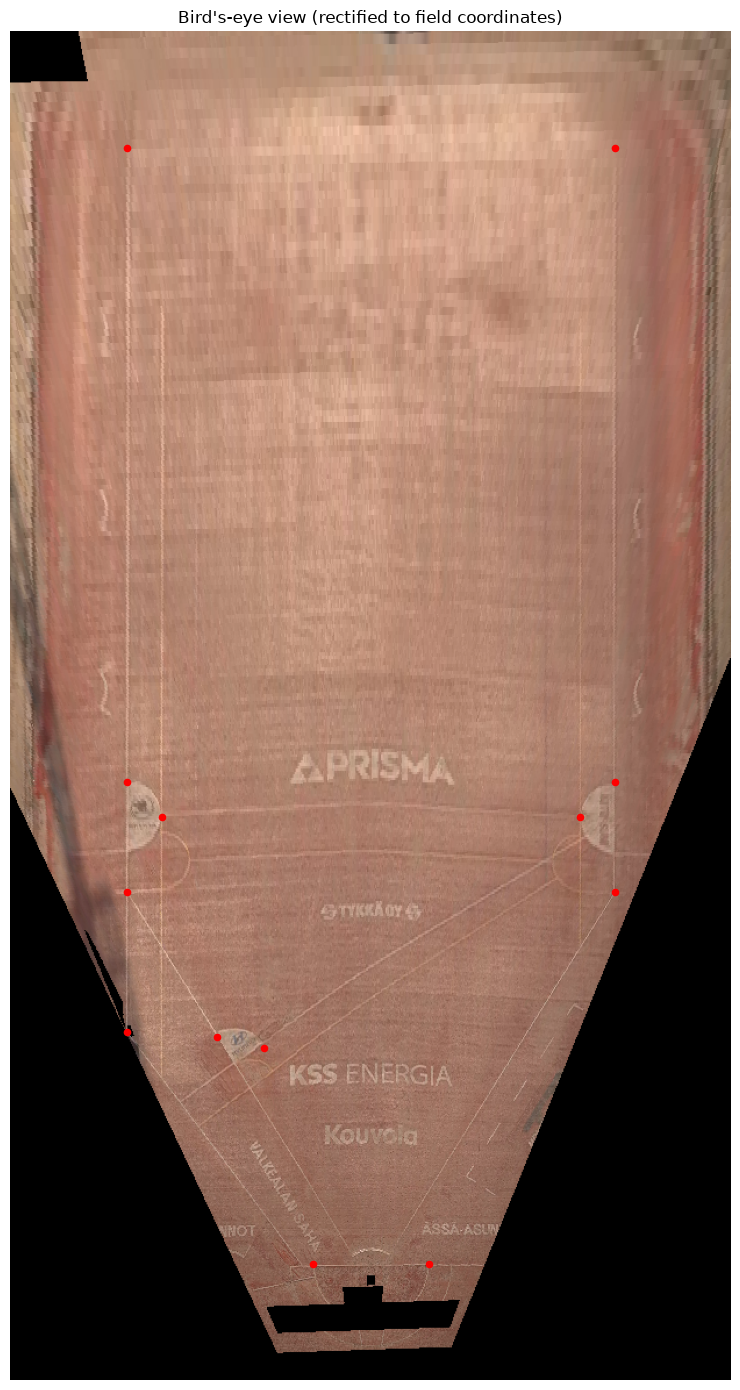

In [46]:
# Sanity check: transform the calibration points into canvas space with the
# same S used above -- they should land back on the same field lines/markings
# visible in the rectified image if the homography is correct.
calib_world_h = np.hstack((points_3d[['x', 'y']].values, np.ones((len(points_3d), 1))))
calib_canvas = (S @ calib_world_h.T).T
calib_canvas = calib_canvas[:, :2] / calib_canvas[:, 2:3]

plt.figure(figsize=(10, 14))
plt.imshow(cv.cvtColor(birdseye, cv.COLOR_BGR2RGB))
plt.scatter(calib_canvas[:, 0], calib_canvas[:, 1], c='red', s=20)
plt.title("Bird's-eye view (rectified to field coordinates)")
plt.axis('off')
plt.tight_layout()
plt.show()
